<a href="https://colab.research.google.com/github/wujh03/MSSP6070/blob/main/WeeklyModules/Week12/Week12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/wujh03/MSSP6070/main/data/Student%20Performance%20Data.csv"

df = pd.read_csv(url)

df.head()

,gender,race/ethnicity,parental level of education,lunch,math score,reading score,writing score,total score,test preparation course,admission prospect
0,female,group B,bachelor's degree,standard,72,72,74,218,none,medium
1,female,group C,some college,standard,69,90,88,247,completed,high
2,female,group B,master's degree,standard,90,95,93,278,none,high
3,male,group A,associate's degree,free/reduced,47,57,44,148,none,low
4,male,group C,some college,standard,76,78,75,229,none,high


In [2]:
print(df.shape)
print(df.columns)

(1000, 10)
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'math score', 'reading score', 'writing score', 'total score',
       'test preparation course', 'admission prospect'],
      dtype='object')


In [3]:
df["average score"] = df["total score"] / 3

df.head()

,gender,race/ethnicity,parental level of education,lunch,math score,reading score,writing score,total score,test preparation course,admission prospect,average score
0,female,group B,bachelor's degree,standard,72,72,74,218,none,medium,72.666667
1,female,group C,some college,standard,69,90,88,247,completed,high,82.333333
2,female,group B,master's degree,standard,90,95,93,278,none,high,92.666667
3,male,group A,associate's degree,free/reduced,47,57,44,148,none,low,49.333333
4,male,group C,some college,standard,76,78,75,229,none,high,76.333333


In [4]:
male = df[df["gender"] == "male"]

completed = male[male["test preparation course"] == "completed"]
none = male[male["test preparation course"] == "none"]

print("Completed:", len(completed))
print("None:", len(none))

print("Completed mean:", completed["average score"].mean())
print("None mean:", none["average score"].mean())

t_stat, p_value = ttest_ind(
    completed["average score"],
    none["average score"],
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

Completed: 174
None: 308
Completed mean: 70.7816091954023
None mean: 63.04437229437229
T-statistic: 6.181421013257206
P-value: 1.7264398970781229e-09


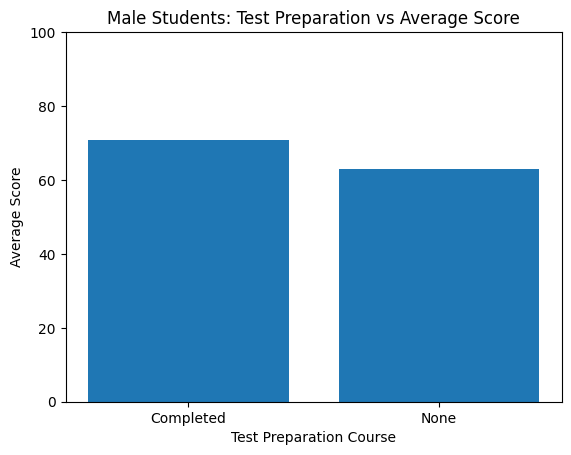

In [5]:
groups = ["Completed", "None"]

means = [
    completed["average score"].mean(),
    none["average score"].mean()
]

plt.bar(groups, means)

plt.title("Male Students: Test Preparation vs Average Score")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")
plt.ylim(0, 100)

plt.show()

In [6]:
female = df[df["gender"] == "female"]

t_stat, p_value = ttest_ind(
    female["average score"],
    male["average score"],
    equal_var=False
)

print("Female mean:", female["average score"].mean())
print("Male mean:", male["average score"].mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

Female mean: 69.56949806949807
Male mean: 65.8374827109267
T-statistic: 4.17888598340718
P-value: 3.1861975638752864e-05


In [7]:
standard = df[df["lunch"] == "standard"]
free = df[df["lunch"] == "free/reduced"]

t_stat, p_value = ttest_ind(
    standard["average score"],
    free["average score"],
    equal_var=False
)

print("Standard mean:", standard["average score"].mean())
print("Free/reduced mean:", free["average score"].mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

Standard mean: 70.83720930232558
Free/reduced mean: 62.199061032863845
T-statistic: 9.32320734961083
P-value: 1.5829690427303388e-19


### Question 2: Is there a statistical difference between males who took the preparation exam and others?

An independent-samples Welch's t-test was conducted to compare the average scores of male students who completed the test preparation course and those who did not.

Male students who completed the course had a higher average score (M = 70.78) than those who did not (M = 63.04). The difference was statistically significant (t = 6.18, p < 0.001).

Therefore, we reject the null hypothesis. There is a statistically significant difference in average scores between the two groups. However, this result does not establish that test preparation caused the difference.

## Question 3: Are there any other differences of interest?

Two additional independent-samples Welch's t-tests were conducted to examine differences in student performance.

**1. Gender Differences**

Female students had a higher average score (M = 69.57) than male students (M = 65.84). The difference was statistically significant (t = 4.18, p < 0.001).

This suggests that overall academic performance differs significantly between male and female students in this dataset.

**2. Lunch Status Differences**

Students receiving standard lunch had a higher average score (M = 70.84) than those receiving free or reduced-price lunch (M = 62.20). The difference was statistically significant (t = 9.32, p < 0.001).

This finding suggests an association between lunch status and academic performance. Lunch status may reflect socioeconomic differences, although this analysis cannot establish causation.

## Overall Conclusion

The t-test results revealed statistically significant differences in average academic performance based on test preparation, gender, and lunch status. Students who completed test preparation generally performed better, female students had higher overall average scores, and students receiving standard lunch scored higher than those receiving free or reduced-price lunch.

However, these findings demonstrate associations rather than causal relationships.